<a href="https://colab.research.google.com/github/jasmidd/MSSP6070/blob/main/WeeklyModules/Week11/Participation_Activity_Week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'jasmidd'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

import subprocess
subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/MSSP6070/MSSP6070


In [25]:
!pip install geojson
!pip install geodatasets
!pip install mapclassify
!pip install cartoframes
%pip install -q geopandas folium mapclassify

  Using cached Jinja2-2.11.3-py2.py3-none-any.whl.metadata (3.5 kB)
Using cached Jinja2-2.11.3-py2.py3-none-any.whl (125 kB)
  Attempting uninstall: jinja2
    Found existing installation: Jinja2 3.1.6
    Uninstalling Jinja2-3.1.6:
      Successfully uninstalled Jinja2-3.1.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jupyter-server 2.20.0 requires jinja2>=3.0.3, but you have jinja2 2.11.3 which is incompatible.
sphinx 8.2.3 requires Jinja2>=3.1, but you have jinja2 2.11.3 which is incompatible.
nbconvert 7.17.2 requires jinja2>=3.0, but you have jinja2 2.11.3 which is incompatible.
flask 3.1.3 requires jinja2>=3.1.2, but you have jinja2 2.11.3 which is incompatible.
flask 3.1.3 requires markupsafe>=2.1.1, but you have markupsafe 2.0.1 which is incompatible.
branca 0.8.2 requires jinja2>=3, but you have jinja2 2.11.3 which is incompatible.
ERROR: pip's dep

In [26]:
import pandas as pd
import geojson as gpd
import geopandas as gp
import matplotlib.pyplot as plt
import mapclassify
import geopandas
import geodatasets
from geodatasets import get_path

In [27]:
df = gp.read_file('/content/MSSP6070/data/california-congressional-districts.geojson')

In [28]:
df['Name'].describe()

,Name
count,53
unique,53
top,01
freq,1


In [29]:
df.head()

,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.66700 39.30511, -121.6301..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


<Axes: >

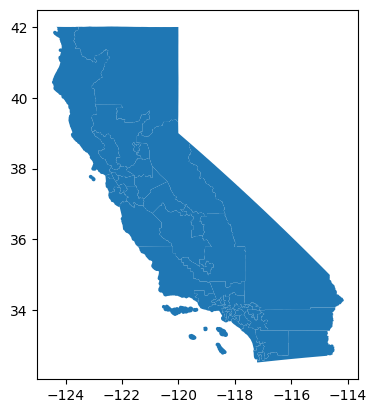

In [30]:
df.plot()

In [31]:
pf = pd.read_csv('/content/MSSP6070/data/CA_Legislative_Districts.csv')

In [32]:
pf.head()

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,...,1|0,0.72,0.14,0.02,0.05,0.75,1|0%,1,2633905.97,122295210592.51
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.66,0.13,0.05,0.17,0.62,10|0%,10,358288.98,2336909010.62
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.75,0.11,0.06,0.32,0.50,11|0%,11,211193.17,940405406.89
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.67,0.14,0.20,0.21,0.42,12|-0%,12,124678.58,586947590.58
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.52,0.50,0.04,0.06,0.37,13|-0%,13,1186867.65,25781145591.73


In [33]:
pf['DISTRICT_N'] = pf['DISTRICT_N'].astype('float64')

In [34]:
df['Name'] = df['Name'].astype('float64')

In [35]:
districts = df.merge(pf, how='left', left_on='Name', right_on='DISTRICT_N')

In [36]:
districts.head()

,Name,description,descriptio,geometry,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1.00,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010...",1.00,1.00,27014.63,1.00,1.00,MTCAP,...,1|0,0.72,0.14,0.02,0.05,0.75,1|0%,1.00,2633905.97,122295210592.51
1,2.00,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967...",12.00,12.00,14613.65,2.00,1.00,NOCST,...,2|1,0.73,0.11,0.02,0.04,0.79,2|0%,2.00,2160287.99,64867518335.60
2,3.00,None,,"MULTIPOLYGON (((-121.66700 39.30511, -121.6301...",23.00,23.00,22035.87,3.00,1.00,YUBA,...,3|-1,0.72,0.10,0.02,0.06,0.80,3|-0%,3.00,2954865.42,91860255906.89
3,4.00,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823...",34.00,34.00,3923.91,4.00,1.00,FTHLL,...,4|-1,0.70,0.20,0.03,0.08,0.67,4|-0%,4.00,1090718.53,16732682078.59
4,5.00,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659...",45.00,45.00,9962.22,5.00,1.00,NEBAY,...,5|-1,0.72,0.18,0.02,0.06,0.71,5|-0%,5.00,1771073.88,41324811434.11


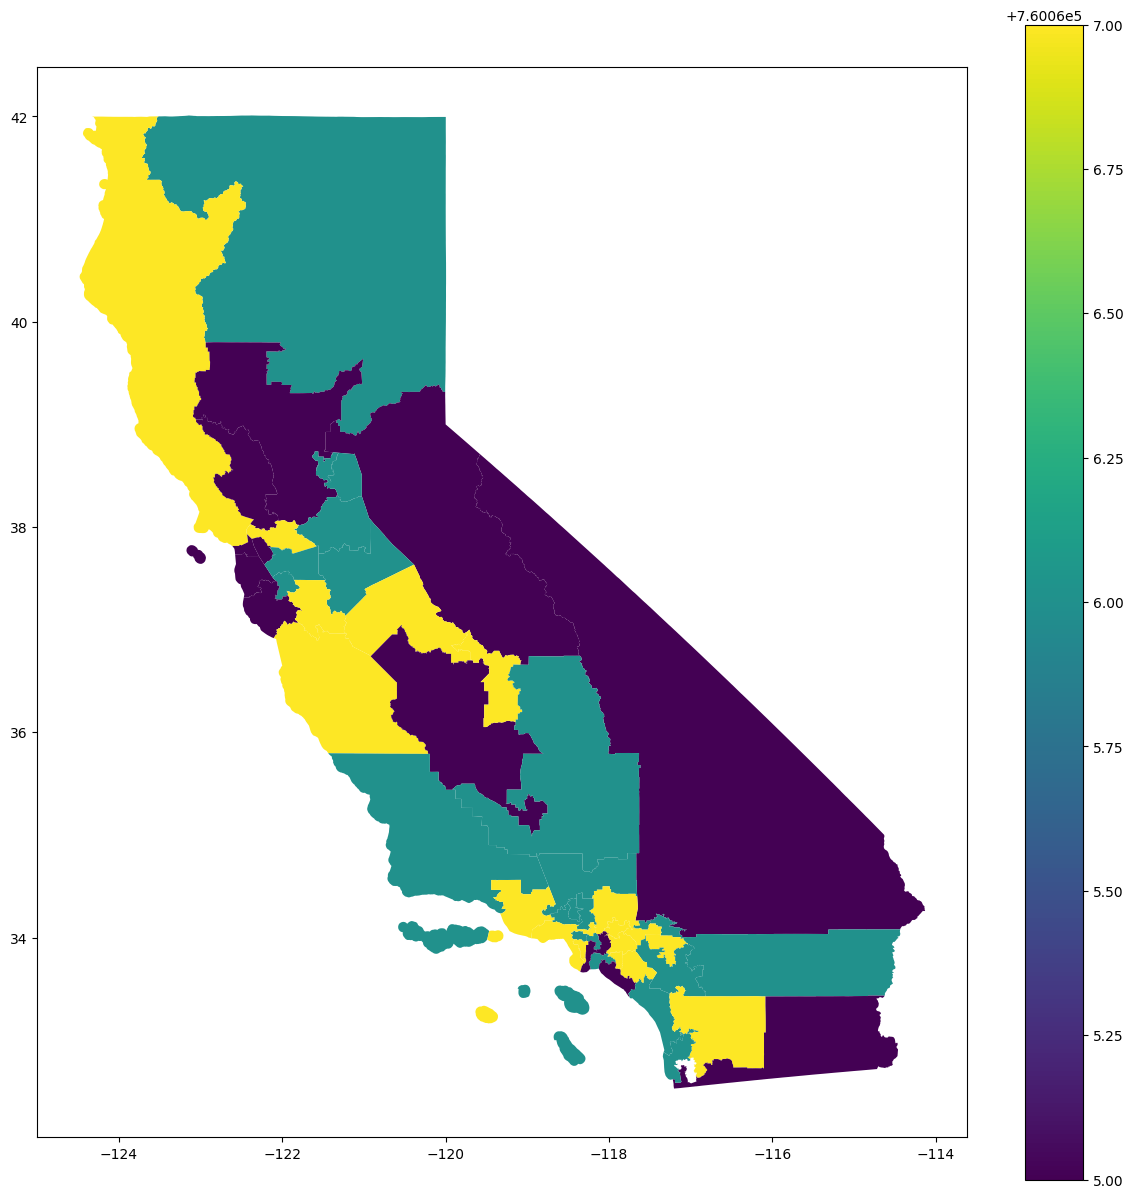

In [37]:
fig, ax2 = plt.subplots(figsize=(15,15))
districts.plot('POPULATION', figsize=(15,15),legend=True, ax=ax2)
fig.show()